In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [2]:
np.random.seed(42)
months = np.arange(1, 61)  # 60 months (5 years of historical data)
trend = 2.5 * months
seasonality = 12 * np.sin(2 * np.pi * months / 12)
noise = np.random.normal(0, 3, size=len(months))
sales = 50 + trend + seasonality + noise

df = pd.DataFrame({'Month': months, 'Sales': sales})
print("--- First 5 Rows of Historical Data ---")
print(df.head())

--- First 5 Rows of Historical Data ---
   Month      Sales
0      1  59.990142
1      2  64.977512
2      3  71.443066
3      4  74.961394
4      5  67.797540


In [3]:
print("\nMissing values check:", df.isnull().sum().to_dict())


Missing values check: {'Month': 0, 'Sales': 0}


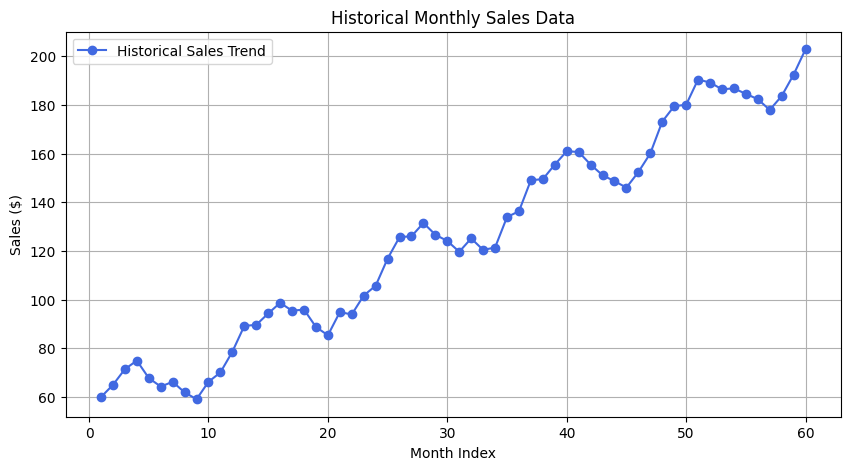

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(df['Month'], df['Sales'], marker='o', color='royalblue', label='Historical Sales Trend')
plt.title('Historical Monthly Sales Data')
plt.xlabel('Month Index')
plt.ylabel('Sales ($)')
plt.grid(True)
plt.legend()
plt.savefig('historical_sales_trend.png')
plt.show()

In [5]:
X = df[['Month']]
y = df['Sales']

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [8]:
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [9]:
print("\n--- Model Evaluation Metrics ---")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R-squared ($R^2$ Score): {r2:.4f}")


--- Model Evaluation Metrics ---
Root Mean Squared Error (RMSE): 9.34
Mean Absolute Error (MAE): 8.07
R-squared ($R^2$ Score): -1.0165


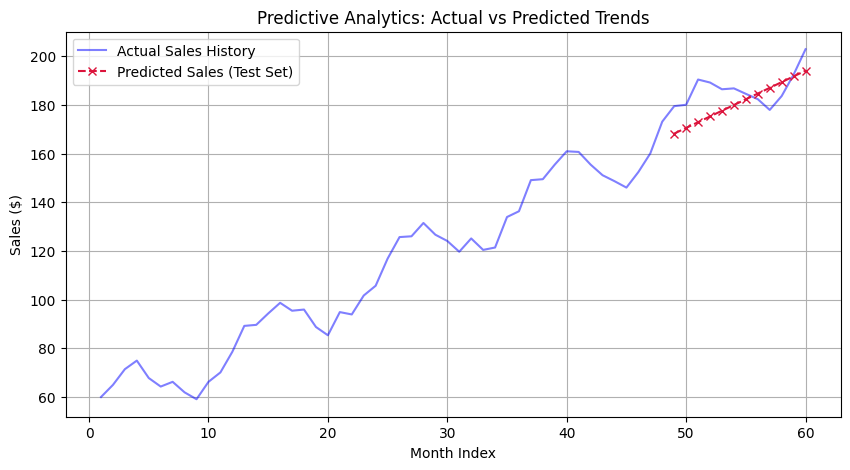

In [10]:
plt.figure(figsize=(10, 5))
plt.plot(df['Month'], df['Sales'], label='Actual Sales History', color='blue', alpha=0.5)
plt.plot(X_test['Month'], y_pred, label='Predicted Sales (Test Set)', color='crimson', linestyle='--', marker='x')
plt.title('Predictive Analytics: Actual vs Predicted Trends')
plt.xlabel('Month Index')
plt.ylabel('Sales ($)')
plt.legend()
plt.grid(True)
plt.savefig('predictive_analytics_results.png')
plt.show()

In [11]:
future_months = np.arange(61, 73).reshape(-1, 1)
future_preds = model.predict(future_months)

print("\n--- Future Sales Forecast (Next 12 Months) ---")
for m, pred in zip(future_months.flatten(), future_preds):
    print(f"Month {m}: Predicted Sales = ${pred:.2f}")


--- Future Sales Forecast (Next 12 Months) ---
Month 61: Predicted Sales = $196.46
Month 62: Predicted Sales = $198.81
Month 63: Predicted Sales = $201.16
Month 64: Predicted Sales = $203.52
Month 65: Predicted Sales = $205.87
Month 66: Predicted Sales = $208.22
Month 67: Predicted Sales = $210.57
Month 68: Predicted Sales = $212.92
Month 69: Predicted Sales = $215.27
Month 70: Predicted Sales = $217.62
Month 71: Predicted Sales = $219.98
Month 72: Predicted Sales = $222.33


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
